## 1. Answer the questions from the Preamble and Introduction

### 1. For which of the models already studied is the curse of dimensionality relevant and explain why.

for KNN and SVM. KNN literally calculates distance between points, SVM (RBF) calculates euclidean distance

### 2. What is the difference between PCA and SVD?

PCA это задача уменьшения размерности, а SVD это метод ее решения

### 3. What is the difference between NMF and SVD?

это разные типы факторизации

SVD говорит нам о том что для любой матрицы существуют две ортогональные и одна диагональная

NMF же говорит, что для матрицы с неотрицательными элементами можно примерно найти разложение на две матрицы с неотрицательными элементами, такое что решение не единственно.


### 4. Describe the structure of the Locally Linear Embedding dimension reduction algorithm.


принцип работы стоит на manifold hypothesis

1. для каждой точки находим k ближайших
2. для каждой точки ищем веса минимизирующие ошибку восстановления х как линейной комбинации ее соседей.
3. дальше для каждых весов ищем точки в низкоразмерном пространстве



## 2. Classification with Sparse Features

### Create a matrix of user-book interactions. Using Sparse Matrices.


In [178]:
import matplotlib.pyplot as plt
import pandas as pd
from scipy.sparse import coo_matrix
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV
from sklearn.decomposition import PCA
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE
from sklearn.manifold import LocallyLinearEmbedding
from sklearn.neighbors import KNeighborsClassifier
from PIL import Image
import cv2
import umap
import time

In [3]:
ratings_df = pd.read_csv(filepath_or_buffer='data/books/Ratings.csv')
ratings_df = ratings_df[ratings_df['Book-Rating'] != 0]

In [4]:
user_cat = ratings_df['User-ID'].astype('category')
book_cat = ratings_df['ISBN'].astype('category')
row_indices = user_cat.cat.codes.values
col_indices = book_cat.cat.codes.values
user_cat

1          276726
3          276729
4          276729
6          276736
7          276737
            ...  
1149773    276704
1149775    276704
1149777    276709
1149778    276721
1149779    276723
Name: User-ID, Length: 433671, dtype: category
Categories (77805, int64): [8, 9, 10, 12, ..., 278849, 278851, 278852, 278854]

In [5]:
n_users = user_cat.cat.categories.size
n_books = book_cat.cat.categories.size
values = ratings_df['Book-Rating'].values


R = coo_matrix(
    (values, (row_indices, col_indices)),
    shape=(n_users, n_books)
)
print(R)

<COOrdinate sparse matrix of dtype 'int64'
	with 433671 stored elements and shape (77805, 185973)>
  Coords	Values
  (77180, 16882)	5
  (77181, 69139)	3
  (77181, 69159)	6
  (77182, 156888)	8
  (77183, 80250)	6
  (77184, 44908)	7
  (77185, 158178)	10
  (77186, 4251)	9
  (77186, 84416)	9
  (77186, 90160)	8
  (77186, 129959)	7
  (77186, 149425)	7
  (77187, 100218)	6
  (77188, 164852)	8
  (77189, 92028)	8
  (77190, 61798)	5
  (77191, 173453)	10
  (77192, 40659)	5
  (77192, 160942)	8
  (77192, 161500)	3
  (77192, 185786)	4
  (77193, 181916)	4
  (77194, 75099)	7
  (77194, 163132)	10
  (77194, 164767)	10
  :	:
  (77175, 71152)	10
  (77175, 74900)	6
  (77175, 75109)	7
  (77175, 75231)	7
  (77175, 75232)	6
  (77175, 82627)	2
  (77175, 84604)	6
  (77175, 90824)	10
  (77175, 90971)	10
  (77175, 92927)	8
  (77175, 97446)	10
  (77175, 106305)	7
  (77175, 117346)	10
  (77175, 117457)	10
  (77175, 125788)	10
  (77175, 134545)	6
  (77175, 141488)	7
  (77176, 30893)	6
  (77176, 42010)	5
  (77176, 9756

### Split the dataset into training, valid, and test parts.


In [6]:
R_csr = R.tocsr()

In [7]:
users_df = pd.read_csv('data/books/Users.csv')

users_df = users_df[
    (users_df['Age'].notna()) &
    (users_df['Age'] >= 10) &
    (users_df['Age'] <= 100)
]

In [8]:
valid_user_ids = set(user_cat.cat.categories) & set(users_df['User-ID'])
print(len(valid_user_ids))

46287


In [9]:
id_to_code = {uid: code for code, uid in enumerate(user_cat.cat.categories)}

valid_indices = [id_to_code[uid] for uid in valid_user_ids]

In [10]:
age_by_id = users_df.set_index('User-ID')['Age']

y = np.array([age_by_id[uid] for uid in valid_user_ids])
X_indices = valid_indices

In [11]:
train_idx, temp_idx, y_train, y_temp = train_test_split(
    X_indices, y, test_size=0.3, random_state=42
)
valid_idx, test_idx, y_valid, y_test = train_test_split(
    temp_idx, y_temp, test_size=0.5, random_state=42
)

X_train = R_csr[train_idx]
X_valid = R_csr[valid_idx]
X_test = R_csr[test_idx]

## Build linear and random forest models to predict user age based on user-book interactions. Do not forget to choose optimal parameters.

In [50]:
alphas = [0.1, 1.0, 10.0, 50.0, 100.0, 500.0, 1000.0, 5000.0, 10000.0, 50000.0]
param_grid = {
    'n_estimators': [50, 100],
    'max_features': ['sqrt', 'log2'],
    'max_depth': [5, 10, 20],
    'min_samples_leaf': [1, 5, 10]
}

In [51]:
def calc_rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

In [52]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def evalu(X_train, y_train, X_valid, y_valid, X_test, y_test):
    best_alpha, best_rmse = None, None
    for alpha in alphas:
        model = Ridge(alpha=alpha, random_state=21)
        model.fit(X_train, y_train)
        preds = model.predict(X_valid)
        rmse = np.sqrt(mean_squared_error(y_valid, preds))
        print(f"alpha={alpha}, valid RMSE={rmse:.3f}")
        if best_rmse is None or rmse < best_rmse:
            best_rmse = rmse
            best_alpha = alpha

    start = time.perf_counter()
    ridge = Ridge(alpha=best_alpha).fit(X_train, y_train)
    ridge_time = time.perf_counter() - start

    grid = GridSearchCV(
    estimator=RandomForestRegressor(random_state=21),
    param_grid=param_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1)

    grid.fit(X_train, y_train)

    return {
        'ridge': {
            'params': {'alpha': best_alpha},
            'valid_rmse': best_rmse,
            'test_rmse': calc_rmse(y_test, ridge.predict(X_test)),
            'fit_time': ridge_time
        },
        'rf': {
            'params': grid.best_params_,
            'valid_rmse': calc_rmse(y_valid, grid.predict(X_valid)),
            'test_rmse': calc_rmse(y_test, grid.predict(X_test)),
            'fit_time': grid.refit_time_
        }
    }


In [53]:
res_raw = evalu(X_train, y_train, X_valid, y_valid, X_test, y_test)

alpha=0.1, valid RMSE=26.992
alpha=1.0, valid RMSE=25.454
alpha=10.0, valid RMSE=23.024
alpha=50.0, valid RMSE=19.363
alpha=100.0, valid RMSE=17.470
alpha=500.0, valid RMSE=14.462
alpha=1000.0, valid RMSE=13.895
alpha=5000.0, valid RMSE=13.504
alpha=10000.0, valid RMSE=13.510
alpha=50000.0, valid RMSE=13.591


In [55]:
res_raw['ridge']

{'params': {'alpha': 5000.0},
 'valid_rmse': np.float64(13.504018038865377),
 'test_rmse': np.float64(13.5602602153554),
 'fit_time': 0.27158549999876413}

In [56]:
res_raw['rf']

{'params': {'max_depth': 20,
  'max_features': 'sqrt',
  'min_samples_leaf': 5,
  'n_estimators': 100},
 'valid_rmse': np.float64(13.61659682323857),
 'test_rmse': np.float64(13.766758102207849),
 'fit_time': 30.827178239822388}

### Use PCA and UMAP to reduce the dimensionality of the features.


In [19]:
pca_books = PCA(n_components=100, random_state=21, svd_solver='arpack')
X_train_pca = pca_books.fit_transform(X_train)
X_valid_pca = pca_books.transform(X_valid)
X_test_pca = pca_books.transform(X_test)

print(X_train.shape, X_train_pca.shape)
print("explained variance:", pca_books.explained_variance_ratio_.sum())

(32400, 185973) (32400, 100)
explained variance: 0.1789423913600987


In [24]:
umap_books = umap.UMAP(n_neighbors=10, n_components=10, random_state=21, n_jobs=-1, low_memory=True)
X_train_imap = umap_books.fit_transform(X_train)
X_valid_imap = umap_books.transform(X_valid)
X_test_imap = umap_books.transform(X_test)

print(X_train_imap.shape, X_valid_imap.shape, X_test_imap.shape)

C:\Users\130\school_21_ds_1\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


(32400, 10) (6943, 10) (6944, 10)


### Build linear model and random forest model on the compressed features.


In [57]:
evalu(X_train_pca, y_train, X_valid_pca, y_valid, X_test_pca, y_test)

alpha=0.1, valid RMSE=13.582
alpha=1.0, valid RMSE=13.582
alpha=10.0, valid RMSE=13.582
alpha=50.0, valid RMSE=13.582
alpha=100.0, valid RMSE=13.582
alpha=500.0, valid RMSE=13.583
alpha=1000.0, valid RMSE=13.584
alpha=5000.0, valid RMSE=13.592
alpha=10000.0, valid RMSE=13.600
alpha=50000.0, valid RMSE=13.627


{'ridge': {'params': {'alpha': 0.1},
  'valid_rmse': np.float64(13.58219715724012),
  'test_rmse': np.float64(13.734931353605056),
  'fit_time': 0.08026800000516232},
 'rf': {'params': {'max_depth': 10,
   'max_features': 'sqrt',
   'min_samples_leaf': 10,
   'n_estimators': 100},
  'valid_rmse': np.float64(13.2594551267117),
  'test_rmse': np.float64(13.463237983166914),
  'fit_time': 60.511085987091064}}

In [58]:
rec_umap = evalu(X_train_imap, y_train, X_valid_imap, y_valid, X_test_imap, y_test)

alpha=0.1, valid RMSE=13.656
alpha=1.0, valid RMSE=13.656
alpha=10.0, valid RMSE=13.656
alpha=50.0, valid RMSE=13.656
alpha=100.0, valid RMSE=13.656
alpha=500.0, valid RMSE=13.656
alpha=1000.0, valid RMSE=13.656
alpha=5000.0, valid RMSE=13.656
alpha=10000.0, valid RMSE=13.656
alpha=50000.0, valid RMSE=13.656


In [59]:
rec_umap['ridge']

{'params': {'alpha': 50000.0},
 'valid_rmse': np.float64(13.655504016680139),
 'test_rmse': np.float64(13.807243769513251),
 'fit_time': 0.0036293999874033034}

In [60]:
rec_umap['rf']

{'params': {'max_depth': 5,
  'max_features': 'sqrt',
  'min_samples_leaf': 5,
  'n_estimators': 100},
 'valid_rmse': np.float64(13.640866219115532),
 'test_rmse': np.float64(13.791490243603208),
 'fit_time': 6.159706115722656}

#### so the quality is almost the same, but fit time is much smaller for umap

# Visualizations



### Load the MNIST dataset

In [8]:
def read_idx(path):
    with open(path, 'rb') as f:
        header = f.read(4)
        assert header[:2] == b'\x00\x00' and header[2] == 8
        ndim = header[3]
        shape = tuple(np.frombuffer(f.read(4 * ndim), dtype='>u4'))
        data = np.frombuffer(f.read(), dtype=np.uint8)
    return data.reshape(shape)

In [9]:
img_train = read_idx('data/nums/train-images.idx3-ubyte')
y_img_train = read_idx('data/nums/train-labels.idx1-ubyte')
img_test = read_idx('data/nums/t10k-images.idx3-ubyte')
y_img_test = read_idx('data/nums/t10k-labels.idx1-ubyte')

In [10]:
img_train

array([[[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       ...,

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 

### Represent each digit image as a vector.

In [11]:
X_img_train = img_train.reshape(len(img_train), -1)
X_img_test = img_test.reshape(len(img_test), -1)

### Transform vectors up to 2 dimensions using PCA, SVD, Randomized-SVD, TSNE, UMAP, and LLE.

In [14]:
idx, other = train_test_split(np.arange(len(X_img_train)), train_size=5000, random_state=21, stratify=y_img_train)

In [15]:
X_s = X_img_train[idx]
y_s = y_img_train[idx]

In [16]:
pca_nums = PCA(n_components=2, random_state=21)
Z_pca = pca_nums.fit_transform(X_s)
Z_pca

array([[ 349.95727135,  397.02336121],
       [ 184.8786494 ,    5.09718632],
       [ 377.55323537,  470.60743114],
       ...,
       [1689.45301154,  402.96460336],
       [ -98.62685011, -729.82148303],
       [ 347.83513759, -453.14878383]], shape=(5000, 2))

In [17]:
U, S, Vt = np.linalg.svd(X_s, full_matrices=False)
Z_svd = X_s @ np.transpose(Vt[:2])
Z_svd

array([[ 1542.69026222,  -287.35913277],
       [ 1189.8269855 ,  -320.80707949],
       [ 1698.17473726,  -272.39163633],
       ...,
       [ 2374.6691081 , -1434.57228607],
       [ 1243.36704306,    20.43583514],
       [ 1157.9794308 ,  -579.42400466]], shape=(5000, 2))

In [18]:
tr_svd = TruncatedSVD(n_components=2, random_state=21, algorithm='randomized')
Z_rand_svd = tr_svd.fit_transform(X_s)
Z_rand_svd

array([[ 1542.69026224,  -287.22474655],
       [ 1189.82698545,  -320.83412871],
       [ 1698.1747372 ,  -272.37167951],
       ...,
       [ 2374.66910801, -1434.59054231],
       [ 1243.36704318,    20.55825845],
       [ 1157.97943085,  -579.38444145]], shape=(5000, 2))

In [19]:
tsne = TSNE(n_components=2, random_state=21)
Z_tsne = tsne.fit_transform(X_s)
Z_tsne

array([[ -2.7773137,  56.581867 ],
       [ 38.166363 ,  28.995602 ],
       [ 27.955393 , -28.347893 ],
       ...,
       [ 77.052704 ,   9.141792 ],
       [-55.033546 , -36.894314 ],
       [ -5.350964 , -56.172043 ]], shape=(5000, 2), dtype=float32)

In [20]:
umap_nums = umap.UMAP(n_components=2, random_state=21)
Z_umap = umap_nums.fit_transform(X_s)
Z_umap

C:\Users\130\school_21_ds_1\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


array([[-1.4459494,  2.568521 ],
       [ 8.387046 ,  1.9830999],
       [ 3.2630584,  0.6028299],
       ...,
       [ 9.693766 ,  6.257013 ],
       [-3.1766806,  8.123748 ],
       [ 0.7968416,  9.188473 ]], shape=(5000, 2), dtype=float32)

In [21]:
lle_nums = LocallyLinearEmbedding(n_components=2, random_state=21)
Z_lle = lle_nums.fit_transform(X_s)
Z_lle

array([[ 0.00360056, -0.00379623],
       [-0.00287782, -0.01915088],
       [-0.00580675, -0.00500251],
       ...,
       [ 0.04416507,  0.0007099 ],
       [-0.0052106 ,  0.02296395],
       [-0.00515692,  0.01904513]], shape=(5000, 2))

### Propose metrics and compare models based on how well they separate digit classes.


In [27]:
def fit_metric_knn_train(Z):
    scores = cross_val_score(knn, Z, y_s)
    return scores.mean()

In [28]:
knn = KNeighborsClassifier(n_neighbors=5)
print(f'pca: {fit_metric_knn_train(Z_pca)}')
print(f'svd: {fit_metric_knn_train(Z_svd)}')
print(f'random: {fit_metric_knn_train(Z_rand_svd)}')
print(f'tsne: {fit_metric_knn_train(Z_tsne)}')
print(f'umap: {fit_metric_knn_train(Z_umap)}')
print(f'lle: {fit_metric_knn_train(Z_lle)}')

pca: 0.41200000000000003
svd: 0.2934
random: 0.294
tsne: 0.9258000000000001
umap: 0.9200000000000002
lle: 0.7852


# Image compression using SVD

### Select 3 random grayscale images and load them into matrix using Python.

In [159]:
img1 = Image.open(fp='data/imgs/img_3.png')
img2 = Image.open(fp='data/imgs/img_1.png')
img3 = Image.open(fp='data/imgs/img_2.png')

In [160]:
arr_img1 = np.array(img1)
arr_img2 = np.array(img2)
arr_img3 = np.array(img3)
print(arr_img1.shape, arr_img2.shape, arr_img3.shape)

(640, 640, 3) (295, 480, 3) (696, 719, 3)


In [161]:
arrr1 = np.dot(arr_img1[:, :, :3], [0.2989, 0.5870, 0.1140])
arrr2 = np.dot(arr_img2[:, :, :3], [0.2989, 0.5870, 0.1140])
arrr3 = np.dot(arr_img3[:, :, :3], [0.2989, 0.5870, 0.1140])

### Vary the rank, compute a low-rank approximation of the original matrix, and plot the recovered image. Use up to 10 different ranks. What does the singular value spectrum look like and how many modes are needed for good image reconstruction?

0 2989 , 05870, 01140

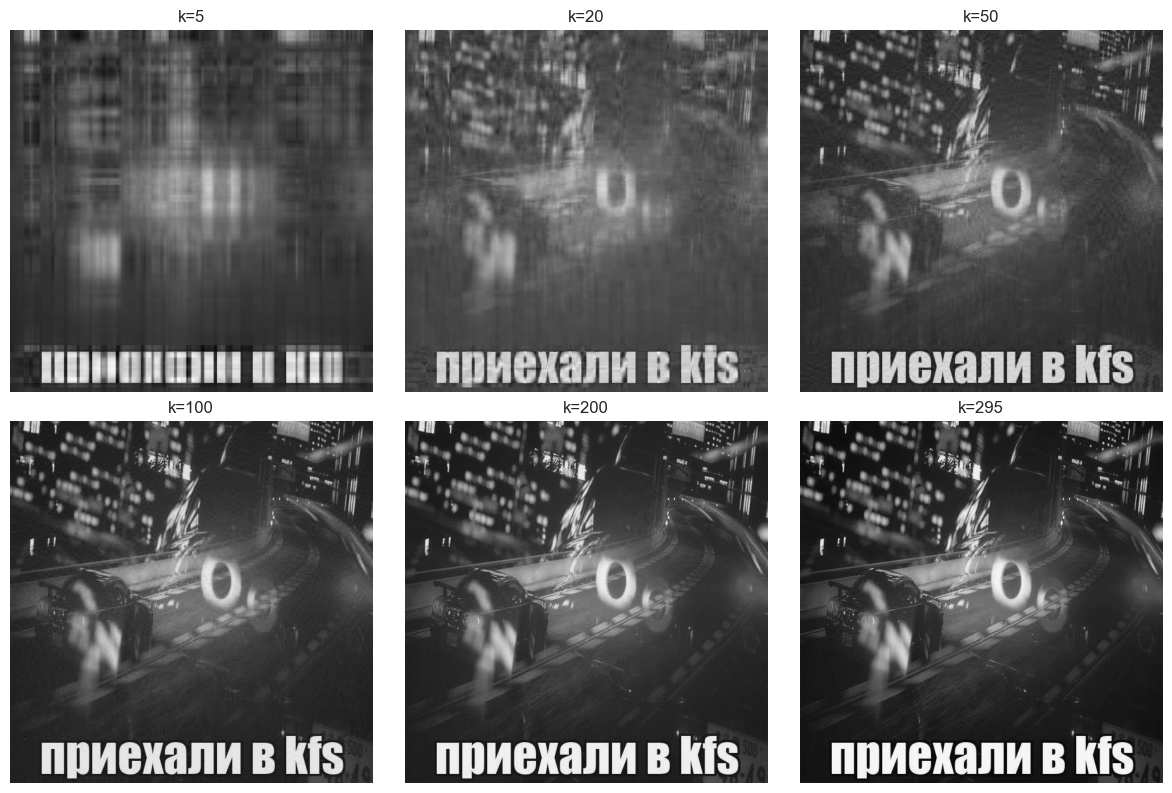

In [273]:
k_rangs = [5, 20, 50, 100, 200, 295]
U, s, Vt = np.linalg.svd(arrr1, full_matrices=False)
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.ravel()
for ax, k in zip(axes, k_rangs):
    compr_img = U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]
    ax.imshow(compr_img, cmap='gray')
    ax.set_title(f'k={k}')
    ax.axis('off')

plt.tight_layout()
plt.show()

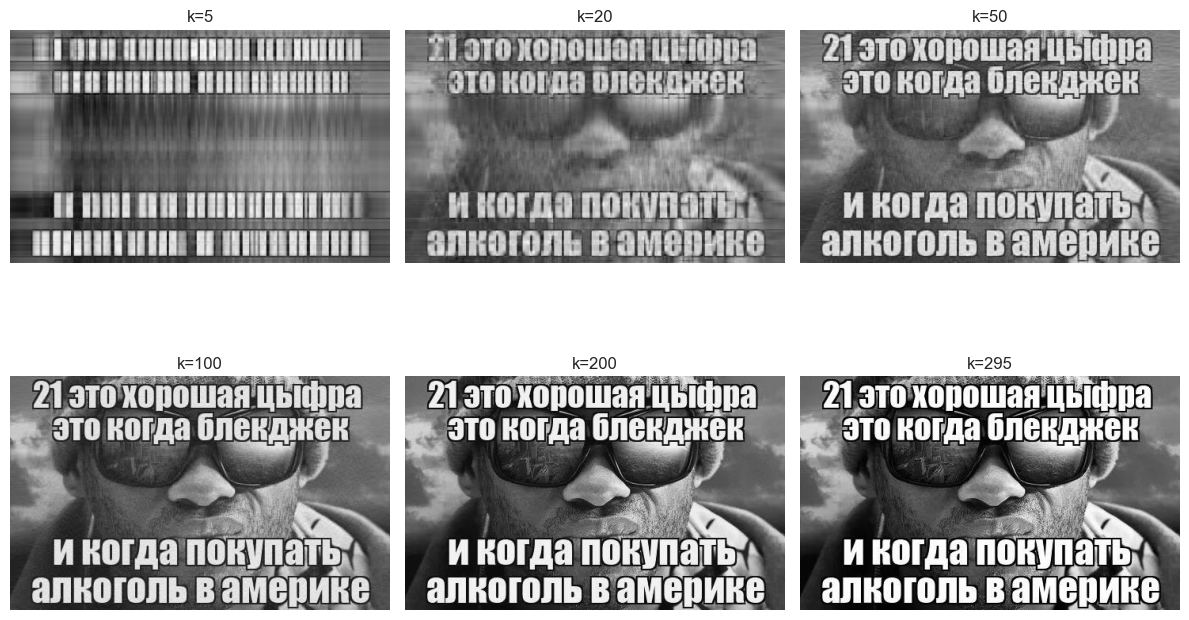

In [272]:
k_rangs = [5, 20, 50, 100, 200, 295]
U, s, Vt = np.linalg.svd(arrr2, full_matrices=False)
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.ravel()
for ax, k in zip(axes, k_rangs):
    compr_img = U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]
    ax.imshow(compr_img, cmap='gray')
    ax.set_title(f'k={k}')
    ax.axis('off')

plt.tight_layout()
plt.show()

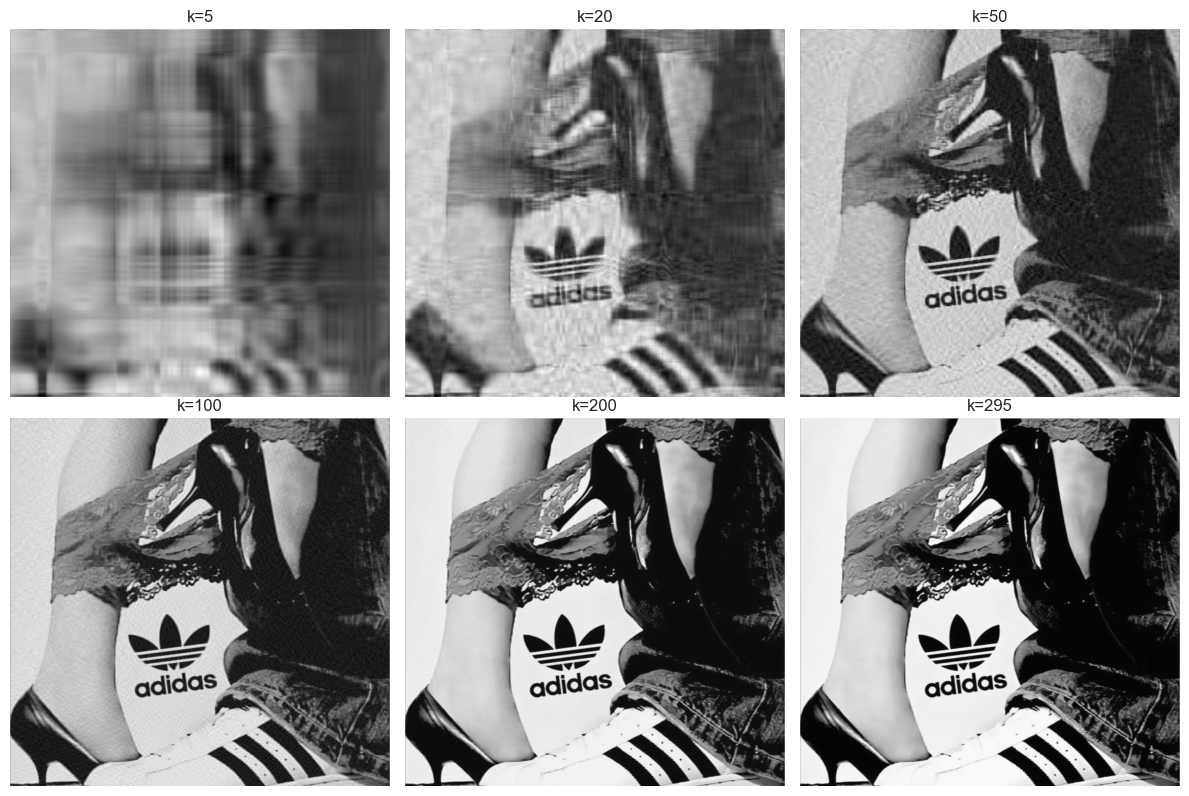

In [270]:
k_rangs = [5, 20, 50, 100, 200, 295]
U, s, Vt = np.linalg.svd(arrr3, full_matrices=False)
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.ravel()
for ax, k in zip(axes, k_rangs):
    compr_img = U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]
    ax.imshow(compr_img, cmap='gray')
    ax.set_title(f'k={k}')
    ax.axis('off')

plt.tight_layout()
plt.show()

15% хватает чтобы было качественное фото

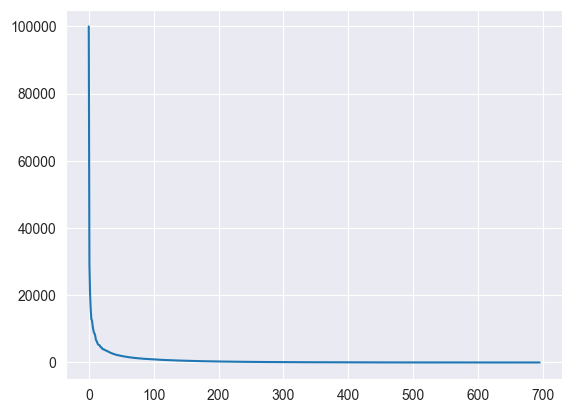

In [167]:
plt.plot(s)
plt.show()

### Plot the distribution of explained variance versus rank. Explain what "explained variance" is.

это доля общей энергии, которую сохраняет приближение ранга k

In [170]:
ei = s**2 / (np.sum(s**2))
ei.sum()

np.float64(1.0000000000000002)

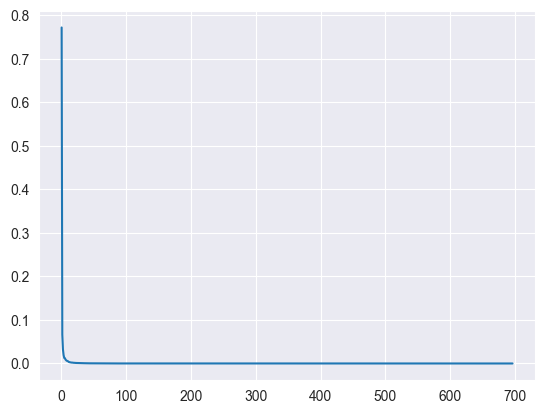

In [173]:
plt.plot(range(1, len(ei)+1), ei)

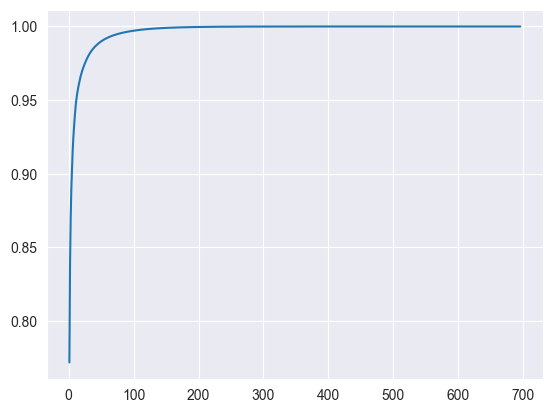

In [176]:
ev = np.cumsum(ei)
plt.plot(range(1, len(ev)+1), ev)

# Background detection using SVD

### Represent the video as a matrix and decompose it using SVD

In [275]:
vid = cv2.VideoCapture('data/Video_008/Video_008.avi')
states = []
frames = []
while True:
    state, frame = vid.read()
    if (state != 1):
        break
    pix = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    states.append(state), frames.append(pix)
vid.release()
print(frames)

[array([[165, 175, 191, ..., 199, 201, 202],
       [175, 186, 200, ..., 196, 199, 199],
       [187, 194, 206, ..., 193, 195, 196],
       ...,
       [115, 107, 104, ..., 116, 111,  87],
       [113, 107, 106, ..., 114,  95,  82],
       [104, 103, 106, ..., 110,  81,  69]], shape=(240, 320), dtype=uint8), array([[170, 179, 192, ..., 198, 200, 201],
       [181, 188, 201, ..., 195, 198, 199],
       [191, 196, 206, ..., 193, 195, 198],
       ...,
       [115, 107, 104, ..., 116, 111,  87],
       [113, 107, 106, ..., 114,  95,  82],
       [104, 103, 106, ..., 110,  81,  69]], shape=(240, 320), dtype=uint8), array([[169, 181, 194, ..., 200, 202, 202],
       [180, 192, 205, ..., 199, 200, 201],
       [192, 201, 212, ..., 196, 198, 198],
       ...,
       [ 72,  32,  58, ...,  89, 102, 114],
       [ 78,  32,  56, ...,  89, 112, 123],
       [ 74,  39,  61, ...,  97, 103, 103]], shape=(240, 320), dtype=uint8), array([[180, 193, 205, ..., 200, 201, 202],
       [191, 201, 213, ..., 

In [276]:
cartinki = np.array(frames)

In [277]:
n, rows, cols = cartinki.shape
pics = cartinki.reshape(n, -1)
pics

array([[165, 175, 191, ..., 110,  81,  69],
       [170, 179, 192, ..., 110,  81,  69],
       [169, 181, 194, ...,  97, 103, 103],
       ...,
       [249, 250, 250, ...,  59,  67,  72],
       [249, 250, 250, ...,  62,  65,  66],
       [249, 250, 250, ...,  64,  57,  60]],
      shape=(792, 76800), dtype=uint8)

In [278]:
U, s, Vt = np.linalg.svd(pics, full_matrices=False)

### Reconstruct the first frame using low-rank approximation. What rank should you use to get the background?

(np.float64(-0.5), np.float64(319.5), np.float64(239.5), np.float64(-0.5))

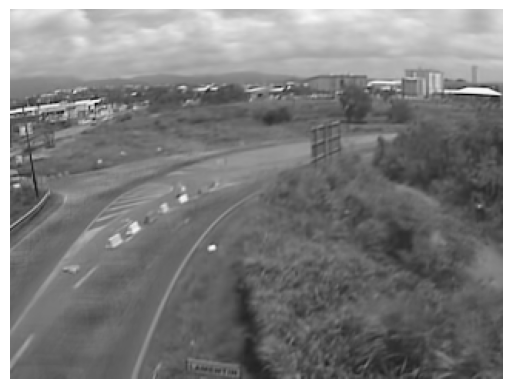

In [291]:
k = 45
first = U[0,:k] @ np.diag(s[:k]) @ Vt[:k, :]
first_arr = first.reshape(rows, cols)
plt.imshow(first_arr, cmap='gray')
plt.axis('off')